In [12]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report,confusion_matrix 



In [13]:
df=pd.read_csv("food_safety.csv")
df.head()

,product_type,packaging_type,shelf_life_days,storage_temperature_C,humidity_level_percent,moisture_content,preservative_level,pH_level,inspection_score_0_100,customer_rating_1_5,product_approval
0,Frozen Food,Paper,345,3.8,44.6,30.1,2.76,6.16,83,4,Approved
1,Canned Food,Vacuum Pack,264,1.2,50.5,19.3,1.99,6.48,83,5,Approved
2,Snacks,Metal,125,0.7,40.9,30.0,5.48,6.51,95,3,Approved
3,Dairy,Plastic,189,0.9,63.3,19.5,4.76,5.21,97,5,Approved
4,Snacks,Paper,44,0.5,67.4,7.3,4.03,5.15,97,5,Approved


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   product_type            500 non-null    object 
 1   packaging_type          500 non-null    object 
 2   shelf_life_days         500 non-null    int64  
 3   storage_temperature_C   500 non-null    float64
 4   humidity_level_percent  500 non-null    float64
 5   moisture_content        500 non-null    float64
 6   preservative_level      500 non-null    float64
 7   pH_level                500 non-null    float64
 8   inspection_score_0_100  500 non-null    int64  
 9   customer_rating_1_5     500 non-null    int64  
 10  product_approval        500 non-null    object 
dtypes: float64(5), int64(3), object(3)
memory usage: 43.1+ KB


In [15]:
df.isnull().sum()

product_type              0
packaging_type            0
shelf_life_days           0
storage_temperature_C     0
humidity_level_percent    0
moisture_content          0
preservative_level        0
pH_level                  0
inspection_score_0_100    0
customer_rating_1_5       0
product_approval          0
dtype: int64

In [21]:
df["product_approval"].value_counts()

product_approval
Approved    250
Rejected    250
Name: count, dtype: int64

In [22]:
df.head()

,product_type,packaging_type,shelf_life_days,storage_temperature_C,humidity_level_percent,moisture_content,preservative_level,pH_level,inspection_score_0_100,customer_rating_1_5,product_approval
0,Frozen Food,Paper,345,3.8,44.6,30.1,2.76,6.16,83,4,Approved
1,Canned Food,Vacuum Pack,264,1.2,50.5,19.3,1.99,6.48,83,5,Approved
2,Snacks,Metal,125,0.7,40.9,30.0,5.48,6.51,95,3,Approved
3,Dairy,Plastic,189,0.9,63.3,19.5,4.76,5.21,97,5,Approved
4,Snacks,Paper,44,0.5,67.4,7.3,4.03,5.15,97,5,Approved


In [17]:
y=df["product_approval"]
x=df.drop(columns="product_approval")

In [23]:
x

,product_type,packaging_type,shelf_life_days,storage_temperature_C,humidity_level_percent,moisture_content,preservative_level,pH_level,inspection_score_0_100,customer_rating_1_5
0,Frozen Food,Paper,345,3.8,44.6,30.1,2.76,6.16,83,4
1,Canned Food,Vacuum Pack,264,1.2,50.5,19.3,1.99,6.48,83,5
2,Snacks,Metal,125,0.7,40.9,30.0,5.48,6.51,95,3
3,Dairy,Plastic,189,0.9,63.3,19.5,4.76,5.21,97,5
4,Snacks,Paper,44,0.5,67.4,7.3,4.03,5.15,97,5
...,...,...,...,...,...,...,...,...,...,...
495,Bakery,Glass,67,15.6,92.4,35.8,2.01,3.51,48,1
496,Ready-to-Eat,Paper,117,24.3,89.8,64.9,1.97,3.36,42,2
497,Juice,Plastic,100,11.3,87.1,45.7,2.68,3.69,42,1
498,Ready-to-Eat,Vacuum Pack,23,14.7,89.5,48.1,0.15,3.12,41,3


In [24]:
y.head()

0    Approved
1    Approved
2    Approved
3    Approved
4    Approved
Name: product_approval, dtype: object

In [25]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


Training data shape: (400, 10)
Testing data shape: (100, 10)


In [26]:
categorical_features=x.select_dtypes(include=["object","category"]).columns.tolist()

numerical_features=x.select_dtypes(include=["int64","float64"]).columns.tolist()

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)


Categorical features:
['product_type', 'packaging_type']

Numerical features:
['shelf_life_days', 'storage_temperature_C', 'humidity_level_percent', 'moisture_content', 'preservative_level', 'pH_level', 'inspection_score_0_100', 'customer_rating_1_5']


In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [28]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [29]:
results = []

trained_pipelines = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    # Create complete pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train
    pipeline.fit(x_train, y_train)

    # Predict
    y_pred = pipeline.predict(x_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    # Store trained pipeline
    trained_pipelines[model_name] = pipeline

    # Classification report
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))



Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Approved       1.00      1.00      1.00        50
    Rejected       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


Training: Naive Bayes

Classification Report:
              precision    recall  f1-score   support

    Approved       1.00      1.00      1.00        50
    Rejected       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


Training: Decision Tree

Classification Report:
              precision    recall  f1-score   support

    Approved       1.00      1.00      1.00        50
    Rejected       1.00      1.00      1.00        50

    accuracy                   

In [30]:
results_df = pd.DataFrame(results)

print("\n\nMODEL COMPARISON")
print("=" * 70)

display(results_df.round(4))




MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0
2,Decision Tree,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0


In [31]:
# Composite score = average of four metrics

results_df["Composite Score"] = results_df[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].mean(axis=1)

results_df = results_df.sort_values(
    by="Composite Score",
    ascending=False
).reset_index(drop=True)

print("\nRANKED MODEL COMPARISON")
print("=" * 70)

display(results_df.round(4))


RANKED MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Composite Score
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0,1.0
2,Decision Tree,1.0,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0,1.0


In [32]:
best_score = results_df["Composite Score"].max()

best_models = results_df[
    results_df["Composite Score"] == best_score
]

print("\nBest Model(s):")
display(
    best_models[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ].round(4)
)


Best Model(s):


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0
2,Decision Tree,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0


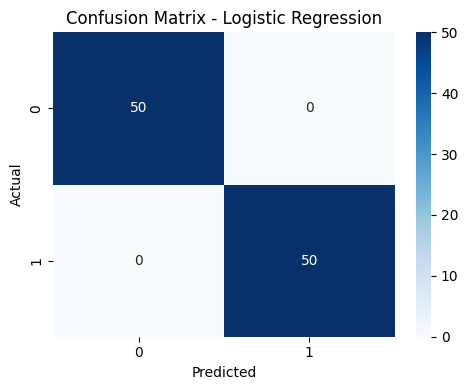

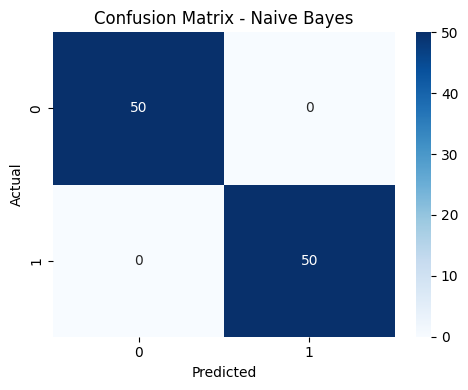

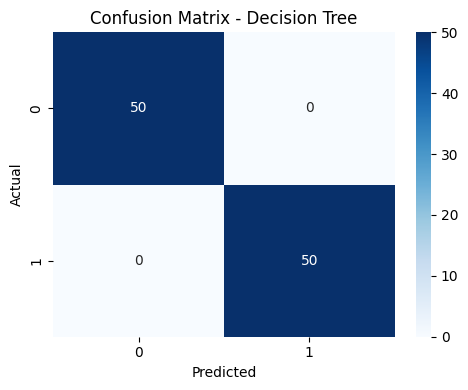

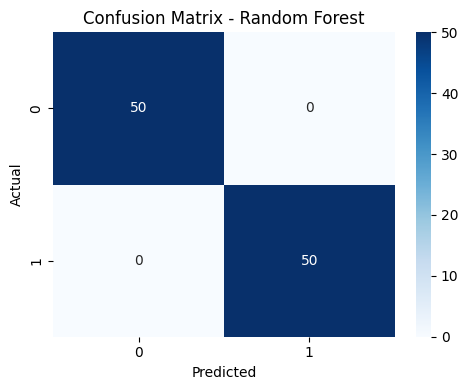

In [33]:
for model_name, pipeline in trained_pipelines.items():

    y_pred = pipeline.predict(x_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

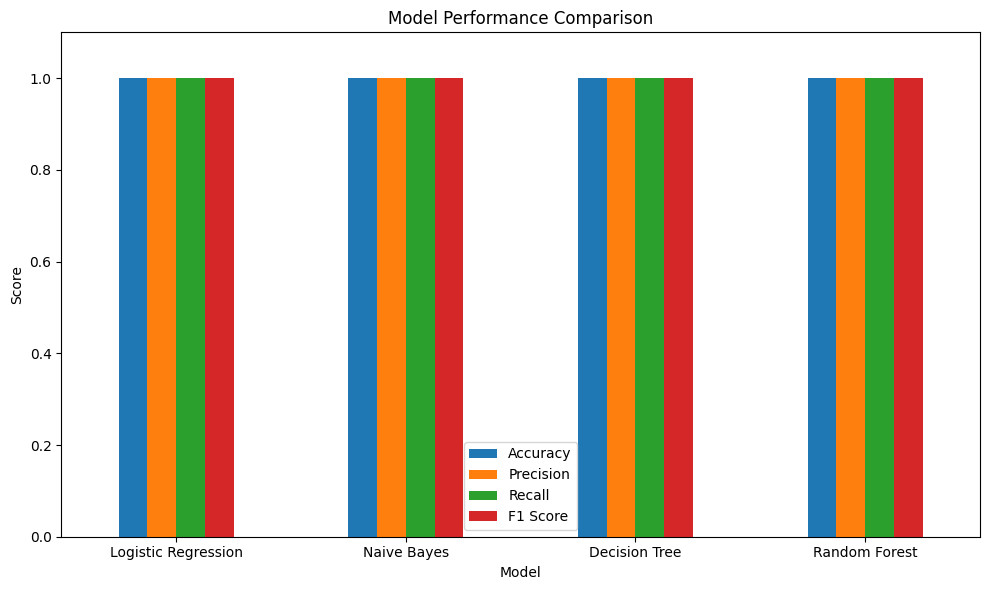

In [34]:
plot_df = results_df.set_index("Model")[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
best_model_name = "Random Forest"

best_model = trained_pipelines[best_model_name]

print("\nBest Model Selected for Deployment:", best_model_name)


 
with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("\nRandom Forest pipeline saved successfully!")
print("File name: best_model.pkl")



Best Model Selected for Deployment: Random Forest

Random Forest pipeline saved successfully!
File name: best_model.pkl


In [36]:
print("\n" + "=" * 70)
print("FINAL MODEL CONCLUSION")
print("=" * 70)

# Random Forest performance
rf_result = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]

print("\nFinal Model: Random Forest")

print(f"Accuracy : {rf_result['Accuracy']:.2f}")
print(f"Precision : {rf_result['Precision']:.2f}")
print(f"Recall : {rf_result['Recall']:.2f}")
print(f"F1 Score : {rf_result['F1 Score']:.2f}")

print("\nConclusion:")
print(
    "Among the four evaluated classification models, "
    "Random Forest was selected as the final model for deployment. "
    "All models achieved identical evaluation scores on the test data. "
    "Therefore, Random Forest was selected as the final model due to "
    "its robustness and suitability for classification tasks."
)

print("\nModel saved as: best_model.pkl")


FINAL MODEL CONCLUSION

Final Model: Random Forest
Accuracy : 1.00
Precision : 1.00
Recall : 1.00
F1 Score : 1.00

Conclusion:
Among the four evaluated classification models, Random Forest was selected as the final model for deployment. All models achieved identical evaluation scores on the test data. Therefore, Random Forest was selected as the final model due to its robustness and suitability for classification tasks.

Model saved as: best_model.pkl
